# Reinforcement Learning with Verifiable Rewards: GRPO

---

> **Post-training series, part 3 of 3:** [Preference Tuning](./08_preference_tuning_rlhf_dpo.ipynb) → [Reasoning at Inference Time](./09_inference_time_scaling_and_evaluation.ipynb) → **RLVR and GRPO**. The three notebooks share one running analogy, a restaurant kitchen; each one opens a different station. [About the series](./00-post-training.md).

Creator: Chung-En Johnny Yu

Content updated: 2026-11-05

Hands-on practice this notebook on your Google Colab:
1. [Click here to open this notebook](https://colab.research.google.com/github/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/10_rlvr_grpo.ipynb)
2. Now, run the code and practice it!

Extends [Preference Tuning](./08_preference_tuning_rlhf_dpo.ipynb) and [Reasoning at Inference Time](./09_inference_time_scaling_and_evaluation.ipynb). The previous notebook sampled several answers and checked them with a verifier, but only to *pick* an answer. **Reinforcement learning with verifiable rewards (RLVR)** uses the same two pieces to *train*: answers the verifier accepts become more likely, the others less likely. GRPO (group relative policy optimization) is the algorithm behind DeepSeek-R1 and most open reasoning models since. This notebook builds GRPO from its parts, runs it on a toy problem, reads Raschka's real training logs on Qwen3-0.6B, and ends with what happens when the verifier can be fooled.

**Sources** — sections taken from Raschka are tagged; everything else is written for this notebook:

| Tag | Source |
|---|---|
| 📗 **[Reasoning Ch6]** | Sebastian Raschka, *Build a Reasoning Model (From Scratch)*, [Chapter 6: Training Reasoning Models with Reinforcement Learning](https://github.com/rasbt/reasoning-from-scratch/blob/main/ch06/01_main-chapter-code/ch06_main.ipynb) — the reward, advantage and policy-gradient code and worked numbers |
| 📗 **[Reasoning Ch7]** | Raschka, [Chapter 7: Improving Policy Optimization](https://github.com/rasbt/reasoning-from-scratch/blob/main/ch07/01_main-chapter-code/ch07_main.ipynb) — clipped ratios, the KL term, metrics to track, the list of GRPO improvements, and the training logs of his runs (copied into `10-rlvr_grpo/data/`) |

Other references, cited where used: DeepSeekMath (Shao et al., 2024), DeepSeek-R1 (2025), DAPO (Yu et al., 2025), Dr. GRPO (Liu et al., 2025), Olmo 3 (2025), DeepSeek-V3.2 (2025).

> **How this notebook works.** We do not train a real model: one GRPO run on Qwen3-0.6B takes hours on a GPU, and Raschka's own runs needed 10–20 GB of memory. Instead, a tiny policy learning to add small numbers shows each mechanism in seconds on CPU, and the real-model behaviour comes from the training logs Raschka published for five GRPO variants, which we load and plot. No model is downloaded; every cell runs on a laptop or Colab CPU in under a minute.

| Part | Content |
|---|---|
| 1 | From RLHF to RLVR: why verifiable rewards changed the recipe |
| 2 | Rewards and group-relative advantages |
| 3 | The GRPO loss: policy gradient, clipping, KL |
| 4 | A toy GRPO run, and why group size matters |
| 5 | Raschka's real runs on Qwen3-0.6B: gains, drift and collapse |
| 6 | Stabilizing GRPO: what the improvements fix |
| 7 | When the verifier can be fooled |
| 8 | Interview-style check questions |

---

In [1]:
import csv, io, math, os, subprocess, sys, urllib.request
try:
    import reasoning_from_scratch  # noqa: F401  (only the verifier is used; no model is loaded)
except ImportError:
    # --no-deps: the package pins an older torch; the verifier only needs sympy, which Colab already has
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--no-deps", "reasoning-from-scratch"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "tokenizers", "sympy"])

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib import patches

import plotly.graph_objects as go
import plotly.io as pio
if "google.colab" not in sys.modules:          # Colab picks its own renderer
    pio.renderers.default = "plotly_mimetype+notebook_connected"

INK, ACCENT, SOFT, BLUE, GREEN, GOLD = "#2b2d42", "#ef8354", "#bfc0c0", "#4f5d75", "#7fb069", "#d7b377"

def fetch(name):
    # Raschka's training logs: local copy -> this repo on GitHub
    local = os.path.join("10-rlvr_grpo", "data", name)
    if os.path.exists(local):
        return open(local, encoding="utf-8").read()
    url = f"https://raw.githubusercontent.com/chungenyu6/ai-learning-notebooks/main/02-LLM/live/10-rlvr_grpo/data/{name}"
    return urllib.request.urlopen(url).read().decode("utf-8")

print("torch", torch.__version__)

torch 2.13.0


## The running analogy: a restaurant kitchen

The post-training series uses one picture: **a restaurant kitchen training an apprentice chef**. Raschka introduces GRPO with a chef analogy too (Chapter 6, §6.2.1). This notebook is the **training kitchen**, where the apprentice practises with a thermometer instead of a critic. The rows for this notebook are in bold.

| In the kitchen | In post-training | Covered in |
|---|---|---|
| a food critic who learned the customers' taste from vote cards | reward model | Preference Tuning |
| cooking to please the critic, with a coach holding you back | RLHF with a KL penalty | Preference Tuning |
| a thermometer and a recipe checklist at the pass | a verifier | Reasoning at Inference Time |
| several cooks make the dish; serve what most of them made | self-consistency | Reasoning at Inference Time |
| **practising with the thermometer instead of the critic** | **reinforcement learning with verifiable rewards (RLVR)** | **RLVR and GRPO** |
| **cooking eight versions of the same dish and comparing each with the batch average** | **GRPO's group-relative advantage** | **RLVR and GRPO** |
| **all eight burnt, or all eight perfect: nothing to learn from the comparison** | **zero advantage, no gradient** | **RLVR and GRPO** |
| **"change your recipe only a little per lesson"** | **clipped policy ratio** | **RLVR and GRPO** |
| **the coach who insists you stay close to how you used to cook** | **the KL term** | **RLVR and GRPO** |
| **a thermometer that sometimes passes an empty plate** | **an exploitable verifier** | **RLVR and GRPO** |

**Where the analogy breaks.** A chef can taste a dish and see *which* step went wrong; GRPO gets one number for the whole answer and spreads the same credit over every token in it, including the bad steps of a lucky answer.

## 1. From RLHF to RLVR

[Preference Tuning](./08_preference_tuning_rlhf_dpo.ipynb) trained on *opinions*: votes, turned into a learned reward model, which the policy then learned to fool. For math and code there is something better than an opinion: a program that checks the answer. Using it as the reward is RLVR.

| | RLHF with PPO | DPO | RLVR with GRPO |
|---|---|---|---|
| reward comes from | a learned reward model | (implicit, from the votes) | a verifier program |
| data needed | preference votes + prompts | preference votes | prompts with checkable answers |
| samples its own answers during training | yes | no (offline) | yes, a **group** per prompt |
| models in memory | policy, reference, reward, value | policy, reference | policy (+ reference if a KL term is used) |
| typical use | helpfulness, style, safety | the same, more cheaply | math, code, anything with a checker |

DeepSeek-R1-Zero showed that RLVR alone, applied to a base model with no supervised reasoning data, makes the model produce longer and longer chains of thought because longer reasoning earns more correct answers (DeepSeek-AI, 2025). One GRPO step:

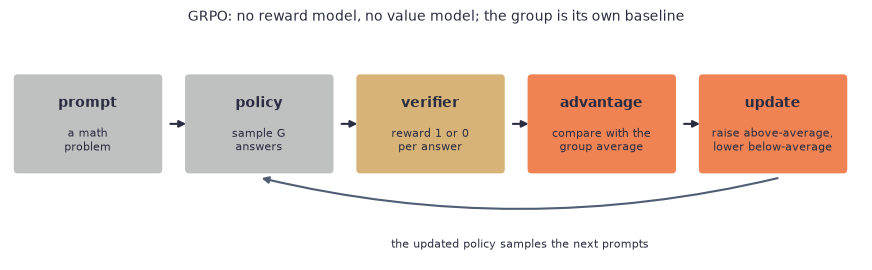

In [2]:
# One GRPO step for one prompt, as kitchen stations
steps_ = [("prompt", "a math\nproblem", SOFT), ("policy", "sample G\nanswers", SOFT), ("verifier", "reward 1 or 0\nper answer", GOLD),
          ("advantage", "compare with the\ngroup average", ACCENT), ("update", "raise above-average,\nlower below-average", ACCENT)]
fig, ax = plt.subplots(figsize=(11, 3.0)); ax.set_xlim(0, 11.2); ax.set_ylim(-0.6, 2.2); ax.axis("off")
for k, (title, sub, color) in enumerate(steps_):
    x = 0.1 + 2.25 * k
    ax.add_patch(patches.FancyBboxPatch((x, 0.5), 1.85, 1.1, boxstyle="round,pad=0.05", fc=color, ec="none"))
    ax.text(x + 0.92, 1.3, title, ha="center", va="center", fontsize=10, weight="bold", color=INK)
    ax.text(x + 0.92, 0.85, sub, ha="center", va="center", fontsize=8, color=INK)
    if k < 4:
        ax.annotate("", xy=(x + 2.25, 1.05), xytext=(x + 1.97, 1.05), arrowprops=dict(arrowstyle="-|>", color=INK, lw=1.5))
ax.annotate("", xy=(3.27, 0.4), xytext=(10.12, 0.4), arrowprops=dict(arrowstyle="-|>", color=BLUE, lw=1.5, connectionstyle="arc3,rad=-0.12"))
ax.text(6.7, -0.45, "the updated policy samples the next prompts", ha="center", fontsize=8, color=INK)
ax.set_title("GRPO: no reward model, no value model; the group is its own baseline", color=INK, fontsize=10)
plt.show()

📗 *[Reasoning Ch6] §6.6 code.* The reward is the verifier from [Reasoning at Inference Time](./09_inference_time_scaling_and_evaluation.ipynb), with one change: `fallback=None` gives reward only to an answer inside `\boxed{}`, an implicit **format** reward.

In [3]:
# Source: Raschka, reasoning-from-scratch Ch6 §6.6 (reward_rlvr and the four example rollouts)
from reasoning_from_scratch.ch03 import extract_final_candidate, grade_answer

def reward_rlvr(answer_text, ground_truth):
    extracted = extract_final_candidate(
        answer_text, fallback=None  # Require \boxed{}
    )
    if not extracted:
        return 0.0
    correct = grade_answer(extracted, ground_truth)
    return float(correct)

rollouts = [r"\boxed{83}", r"The correct answer is \boxed{83}", r"The final answer is 83", r"We get \boxed{38}"]
rollout_rewards = [reward_rlvr(a, ground_truth="83") for a in rollouts]
for a, r in zip(rollouts, rollout_rewards):
    print(f"reward {r}   {a}")
assert rollout_rewards == [1.0, 1.0, 0.0, 0.0]

reward 1.0   \boxed{83}
reward 1.0   The correct answer is \boxed{83}
reward 0.0   The final answer is 83
reward 0.0   We get \boxed{38}


"The final answer is 83" is right but earns nothing: during training the model must also learn the output format the verifier expects. DeepSeek-R1's team also tried rewarding intermediate steps with a process reward model and concluded that final-answer rewards worked better (Raschka, Ch6 §6.6).

**In the kitchen.** The thermometer replaces the critic: it cannot be flattered, it only checks the one thing it was built to check.

## 2. Rewards and group-relative advantages

PPO needs a value model to decide whether an answer was better than expected. GRPO's trick is to sample a **group** of $G$ answers to the same prompt and use the group itself as the baseline:

$$
A_i=\frac{r_i-\mu_r}{\sigma_r+\epsilon},\qquad \mu_r,\ \sigma_r = \text{mean and standard deviation of the } G \text{ rewards}.
$$

**By hand** for the four rollouts above, rewards $[1,1,0,0]$: $\mu_r = 0.5$ and the sample standard deviation is $\sigma_r=\sqrt{\tfrac{4\cdot0.25}{3}}\approx0.577$, so every right answer gets $A=0.5/0.577\approx+0.866$ and every wrong one $-0.866$.

📗 *[Reasoning Ch6] §6.7 code:*

In [4]:
# Source: Raschka, reasoning-from-scratch Ch6 §6.7
rewards = torch.tensor(rollout_rewards)
advantages = (rewards - rewards.mean()) / (rewards.std() + 1e-4)
print(advantages)
assert torch.allclose(advantages, torch.tensor([0.8659, 0.8659, -0.8659, -0.8659]), atol=1e-4)

tensor([ 0.8659,  0.8659, -0.8659, -0.8659])


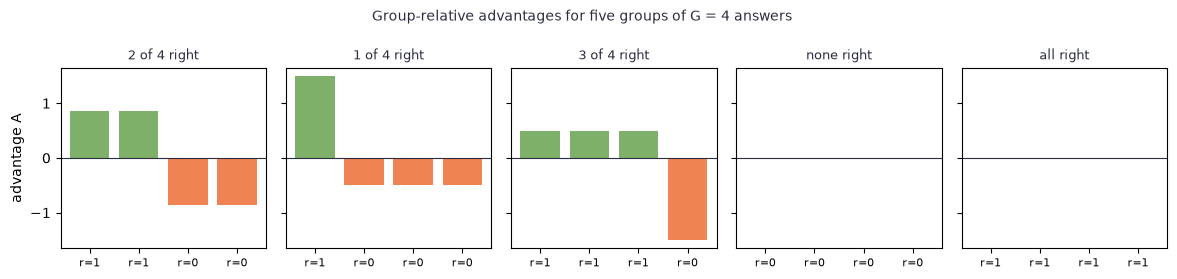

In [5]:
# How the advantage depends on the group: a rare success is worth a lot, a uniform group is worth nothing
groups = {"2 of 4 right": [1, 1, 0, 0], "1 of 4 right": [1, 0, 0, 0], "3 of 4 right": [1, 1, 1, 0],
          "none right": [0, 0, 0, 0], "all right": [1, 1, 1, 1]}
fig, axes = plt.subplots(1, len(groups), figsize=(12, 2.8), sharey=True)
for ax, (name, r) in zip(axes, groups.items()):
    r = torch.tensor(r, dtype=torch.float)
    adv = (r - r.mean()) / (r.std() + 1e-4)
    ax.bar(range(4), adv, color=[GREEN if v > 0 else ACCENT if v < 0 else SOFT for v in adv])
    ax.axhline(0, color=INK, lw=0.8); ax.set_xticks(range(4), [f"r={int(v)}" for v in r], fontsize=8)
    ax.set_title(name, fontsize=9, color=INK)
axes[0].set_ylabel("advantage A")
fig.suptitle("Group-relative advantages for five groups of G = 4 answers", color=INK, fontsize=10)
plt.tight_layout(); plt.show()

- The **only** right answer in a group gets $A=+1.5$: rare successes teach the most.
- **All wrong or all right gives zero advantage for every answer**, so that prompt contributes no gradient at all. Too-hard and too-easy prompts are wasted compute, which is why practitioners filter prompts by difficulty and why group size matters (Part 4).
- The advantages always average to zero: GRPO only says "more like the better answers in this group", never "this is good in absolute terms".

<details><summary><b>Quick check:</b> rewards $[0, 0, 0, 1]$. Which answer is pushed up, and by how much compared with the $[1, 1, 0, 0]$ case?</summary>

The fourth answer: $\mu_r=0.25$, $\sigma_r=0.5$, so $A_4=(1-0.25)/0.5=+1.5$ versus $+0.866$; the three wrong answers each get $-0.5$. One success among failures is a strong signal.
</details>

**In the kitchen.** The apprentice cooks four versions; the ones better than the batch average are what to do more of. If all four are burnt, the comparison teaches nothing.

## 3. The GRPO loss

Each answer's advantage multiplies the log-probability of the whole answer under the policy (the sum over its tokens, as in [Preference Tuning](./08_preference_tuning_rlhf_dpo.ipynb)):

$$
\mathcal{L}_{\text{PG}}=-\frac{1}{G}\sum_{i=1}^{G} A_i\,\log\pi_\theta(y_i\mid x),\qquad \log\pi_\theta(y_i\mid x)=\sum_t \log\pi_\theta\big(y_{i,t}\mid x, y_{i,<t}\big).
$$

Minimizing it raises the probability of above-average answers and lowers the others. This is REINFORCE with the group mean as baseline.

📗 *[Reasoning Ch6] §6.9 code*, with the sequence log-probabilities Raschka measured for the four rollouts:

In [6]:
# Source: Raschka, reasoning-from-scratch Ch6 §6.8–6.9 (log-probabilities of the four rollouts, policy-gradient loss)
logps = torch.tensor([-7.9243, -20.1546, -16.6130, -23.3677])
pg_loss = -(advantages.detach() * logps).mean()
print("policy-gradient loss:", round(pg_loss.item(), 4))
assert math.isclose(pg_loss.item(), -2.5764, abs_tol=1e-3)

policy-gradient loss: -2.5764


📗 *[Reasoning Ch7] §7.4.* **Clipping**, as in PPO ([Preference Tuning](./08_preference_tuning_rlhf_dpo.ipynb), Part 4): when the same rollouts are used for several updates, compare the new log-probabilities with those of the policy that generated them, $\rho_i=\exp(\log\pi_\theta-\log\pi_{\text{old}})$, and clip $\rho$ to $[1-\epsilon, 1+\epsilon]$ so no single answer can move the policy too far in one step. Raschka's example, using DeepSeek-R1's very loose $\epsilon = 10$:

In [7]:
# Source: Raschka, reasoning-from-scratch Ch7 §7.4.1 (old/new log-probabilities and the clipped objective)
new_logps = logps
old_logps = torch.tensor([-10.9243, -20.3546, -14.6130, -23.3677])
ratio = torch.exp(new_logps - old_logps)
clip_eps = 10.0
clipped_ratio = torch.clamp(ratio, 1.0 - clip_eps, 1.0 + clip_eps)
adv = advantages.detach()
clipped_pg_loss = -torch.mean(torch.minimum(ratio * adv, clipped_ratio * adv))
print("ratio:        ", [round(v, 4) for v in ratio.tolist()])
print("clipped ratio:", [round(v, 4) for v in clipped_ratio.tolist()])
print("clipped policy-gradient loss:", round(clipped_pg_loss.item(), 4))
assert math.isclose(clipped_pg_loss.item(), -2.3998, abs_tol=1e-3)

ratio:         [20.0855, 1.2214, 0.1353, 1.0]
clipped ratio: [11.0, 1.2214, 0.1353, 1.0]
clipped policy-gradient loss: -2.3998


The first rollout became $e^3\approx20$ times more likely; clipping caps its influence at $1+\epsilon=11$.

📗 *[Reasoning Ch7] §7.5.* **The KL term.** The original GRPO adds the same "stay close to the reference" penalty as RLHF, computed from the log-probabilities of the same answers under the frozen starting model:

$$
\mathcal{L}=\mathcal{L}_{\text{PG}}+\beta_{\text{KL}}\cdot\frac{1}{G}\sum_i\big(\log\pi_\theta(y_i)-\log\pi_{\text{ref}}(y_i)\big).
$$

It needs a second copy of the model in memory, and, as Part 5 shows, it can hurt more than help on math.

Variants differ in whether the ratio is computed per token or per whole answer (📗 Raschka's overview, Ch7 §7.4.1):

| Method | Ratio computed per |
|---|---|
| DeepSeekMath GRPO (2024) | token |
| DeepSeek-R1 GRPO (2025) | whole answer (sequence) |
| DAPO (2025) | token |
| GSPO (2025) | sequence, length-normalized |

**In the kitchen.** Clipping is "change the recipe only a little per lesson"; the KL term is the coach who wants you to keep cooking the way you were taught.

## 4. A toy GRPO run, and why group size matters

A real GRPO step generates hundreds of tokens per answer. To see the dynamics in seconds, our "language model" answers in **one token**: given two digits $a, b \in \{0,\dots,4\}$ it picks an answer from $0$–$8$ (or an empty box, used in Part 7). The verifier checks $a+b$.

Like a real base model, the starting policy is already sometimes right: we first train it briefly on noisy demonstrations, which leaves it right about 16% of the time (printed below; Qwen3-0.6B base starts at 15.6% on MATH-500). Then GRPO takes over, with exactly the advantage and loss code above.

In [8]:
K, EMPTY, N_ACT = 5, 9, 10            # digits 0..4; answers 0..8; action 9 = an empty \boxed{}

class TinyPolicy(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(2 * K + 1, 64), nn.Tanh(), nn.Linear(64, N_ACT))
    def forward(self, a, b, hard):        # 'hard' marks problems used in Part 7
        return self.net(torch.cat([F.one_hot(a, K), F.one_hot(b, K), hard[:, None].float()], -1))

def make_problems(n, g, hard_frac=0.0):
    a, b = torch.randint(0, K, (n,), generator=g), torch.randint(0, K, (n,), generator=g)
    hard = torch.rand(n, generator=g) < hard_frac
    # a 'hard' problem's answer depends on something the policy cannot see, so it can only guess
    target = torch.where(hard, torch.randint(0, 9, (n,), generator=g), a + b)
    return a, b, hard, target

def base_policy(seed=0):
    # "pretraining": imitate demonstrations that are right 35% of the time, occasionally with an empty box
    torch.manual_seed(seed); g = torch.Generator().manual_seed(100 + seed)
    pol = TinyPolicy(); opt = torch.optim.Adam(pol.parameters(), lr=1e-2)
    for _ in range(300):
        a, b, hard, target = make_problems(256, g, hard_frac=0.5)
        u = torch.rand(256, generator=g)
        y = torch.where(u < 0.35, target, torch.randint(0, 9, (256,), generator=g))
        y = torch.where(u > 0.92, torch.full_like(y, EMPTY), y)
        loss = F.cross_entropy(pol(a, b, hard), y)
        opt.zero_grad(); loss.backward(); opt.step()
    return pol

A_ALL, B_ALL = torch.arange(K).repeat_interleave(K), torch.arange(K).repeat(K)

@torch.no_grad()
def evaluate(pol):
    # exact probabilities over all 25 problems: accuracy on solvable problems, empty-box rate on hard / solvable ones
    p_easy = F.softmax(pol(A_ALL, B_ALL, torch.zeros(K * K, dtype=torch.bool)), -1)
    p_hard = F.softmax(pol(A_ALL, B_ALL, torch.ones(K * K, dtype=torch.bool)), -1)
    return p_easy[torch.arange(K * K), A_ALL + B_ALL].mean().item(), p_hard[:, EMPTY].mean().item(), p_easy[:, EMPTY].mean().item()

def train_grpo(G=8, steps=300, batch=16, lr=1e-2, hard_frac=0.0, loophole=0.0, seed=0):
    torch.manual_seed(seed); g = torch.Generator().manual_seed(seed)
    pol = base_policy(seed); opt = torch.optim.Adam(pol.parameters(), lr=lr)
    log = []
    for _ in range(steps):
        a, b, hard, target = make_problems(batch, g, hard_frac)
        logits = pol(a, b, hard)
        answers = torch.distributions.Categorical(logits=logits).sample((G,)).T       # (batch, G): a group per prompt
        correct = (answers == target[:, None]).float()
        fooled = (answers == EMPTY).float() * (torch.rand(answers.shape, generator=g) < loophole).float()
        r = torch.maximum(correct, fooled)                                          # what the verifier says
        adv = (r - r.mean(1, keepdim=True)) / (r.std(1, keepdim=True) + 1e-4)        # group-relative advantage
        logp = torch.gather(F.log_softmax(logits, -1), 1, answers)
        loss = -(adv.detach() * logp).mean()                                        # policy-gradient loss
        opt.zero_grad(); loss.backward(); opt.step()
        log.append((r.mean().item(), correct.mean().item(), (r.std(1) == 0).float().mean().item(), *evaluate(pol)))
    return np.array(log)   # columns: verifier reward, truly correct, zero-signal groups, accuracy, P(empty|hard), P(empty|easy)

print("starting accuracy:", round(evaluate(base_policy())[0], 2))

starting accuracy: 0.16


How large should the group be? Drag $G$; each setting is a separate 300-step run (precomputed, about a second each).

In [9]:
# Interactive: drag the group size G. Accuracy, and the share of prompts whose group gave no learning signal.
Gs = [2, 4, 8, 16, 32]
runs = {G: train_grpo(G=G) for G in Gs}
default = Gs.index(8)
fig = go.Figure(); titles = []
steps_x = list(range(1, 301))
smooth = lambda v, w=15: np.convolve(v, np.ones(w) / w, mode="valid")
for G in Gs:
    L = runs[G]; vis = G == Gs[default]
    fig.add_scatter(x=steps_x, y=L[:, 3], name="accuracy (exact, all 25 problems)", line=dict(color=GREEN, width=3), visible=vis)
    fig.add_scatter(x=steps_x[14:], y=smooth(L[:, 2]), name="prompts with no signal (all same reward)", line=dict(color=ACCENT, dash="dash"), visible=vis)
    titles.append(f"G = {G}: accuracy {L[0, 3]:.2f} → {L[49, 3]:.2f} at step 50 → {L[-1, 3]:.2f} at step 300; "
                  f"{L[:50, 2].mean():.0%} of early prompts give no signal")
steps = [dict(method="update", label=str(G), args=[{"visible": [j // 2 == i for j in range(2 * len(Gs))]}, {"title.text": titles[i]}])
         for i, G in enumerate(Gs)]
fig.update_layout(height=420, title=titles[default], xaxis_title="GRPO step", yaxis=dict(range=[0, 1.02]),
                  legend=dict(x=0.5, y=0.45), sliders=[dict(active=default, steps=steps, pad={"t": 50}, currentvalue={"prefix": "G = "})])
fig.show()

In [10]:
print(f"{'G':>3s} {'step 1':>7s} {'step 50':>8s} {'step 300':>9s} {'no-signal prompts, first 50 steps':>35s} {'answers sampled':>16s}")
for G, L in runs.items():
    print(f"{G:3d} {L[0, 3]:7.2f} {L[49, 3]:8.2f} {L[-1, 3]:9.2f} {L[:50, 2].mean():35.0%} {300 * 16 * G:16,d}")

  G  step 1  step 50  step 300   no-signal prompts, first 50 steps  answers sampled
  2    0.16     0.33      0.74                                 72%            9,600
  4    0.16     0.48      0.79                                 40%           19,200
  8    0.16     0.50      0.87                                 19%           38,400
 16    0.16     0.55      0.80                                  5%           76,800
 32    0.16     0.54      0.92                                  1%          153,600


- With $G = 2$, most early groups are "both wrong" or "both right", so most prompts teach nothing and learning is slow.
- Larger groups find a right answer (and a wrong one) in more prompts, so more prompts give a signal.
- Each extra answer costs a full generation, so $G$ is a compute trade-off. Raschka's runs use 8 answers per prompt; DeepSeek-R1 reports 16.
- Late in training the share of no-signal prompts rises again: the policy now gets them *all* right. At that point a real run needs harder prompts, the reason DAPO filters out prompts that are always solved or never solved.

**In the kitchen.** Cooking two versions per lesson rarely gives one good and one bad; cooking eight usually does, at four times the effort.

## 5. Raschka's real runs on Qwen3-0.6B

📗 *[Reasoning Ch7] training logs.* Raschka trained the same Qwen3-0.6B base model as in [Reasoning at Inference Time](./09_inference_time_scaling_and_evaluation.ipynb) on 12,000 MATH training problems, 8 rollouts per prompt, up to 1,024 new tokens per answer, for 500 steps, and logged every step. MATH-500 accuracy was evaluated every 50 steps. Four variants, each adding one change to the previous one:

| Run | What changes |
|---|---|
| GRPO, no KL (Ch6, with Ch7 tracking) | the loss from Part 3, no clipping, no KL |
| + clipped ratio (Ch7 §7.4) | two updates per batch of rollouts, ratios clipped at $1\pm10$ |
| + KL term (Ch7 §7.5) | adds a KL penalty to the starting model (a second, frozen copy of it) |
| + format reward (Ch7 §7.6) | starts from the *reasoning* model and adds a reward for `<think>…</think>` tags |

In [11]:
def load_log(name):
    rows = list(csv.DictReader(io.StringIO(fetch(name))))
    cols = {k: np.array([float(r[k]) if r.get(k) else np.nan for r in rows]) for k in rows[0]}
    return cols

logs = {"GRPO, no KL": load_log("7_3_plus_tracking_metrics.csv"),
        "+ clipped ratio": load_log("7_4_plus_clip_ratio_metrics.csv"),
        "+ KL term": load_log("7_5_plus_kl_metrics.csv"),
        "+ format reward (reasoning model)": load_log("7_6_plus_format_reward_metrics.csv")}
print(f"{'run':36s} " + " ".join(f"{s:>6d}" for s in [1, 50, 100, 200, 300, 400, 500]) + "   (MATH-500 accuracy %, by step)")
for name, L in logs.items():
    acc = {int(s): a for s, a in zip(L["step"], L["eval_acc"]) if not np.isnan(a)}
    row = [acc.get(s, acc.get(s - 1, np.nan)) for s in [1, 50, 100, 200, 300, 400, 500]]
    print(f"{name:36s} " + " ".join(f"{v:6.1f}" for v in row))

run                                       1     50    100    200    300    400    500   (MATH-500 accuracy %, by step)
GRPO, no KL                            15.6   46.2   43.4   44.2   37.0   38.0   33.0
+ clipped ratio                        15.6   45.2   45.6   42.4   42.4   41.8   41.6
+ KL term                              15.6   40.8    0.0    0.0    0.0    0.0    0.0
+ format reward (reasoning model)      50.8   56.2   54.8   32.2    9.4   29.6   35.0


In [12]:
# Interactive: switch the metric. Smoothed per-step training metrics of Raschka's four runs (MATH-500 accuracy every 50 steps).
colors = {"GRPO, no KL": BLUE, "+ clipped ratio": GREEN, "+ KL term": ACCENT, "+ format reward (reasoning model)": GOLD}
metrics = [("eval_acc", "MATH-500 accuracy (%)"), ("reward_avg", "training reward (share of correct rollouts)"),
           ("avg_response_len", "average response length (tokens)"), ("entropy_avg", "average next-token entropy (nats)")]
def smooth_nan(v, w=20):
    out = np.full_like(v, np.nan); ok = ~np.isnan(v)
    vals = v[ok]; sm = np.array([vals[max(0, i - w + 1): i + 1].mean() for i in range(len(vals))])
    out[np.where(ok)[0]] = sm; return out
fig = go.Figure()
for m, (col, label) in enumerate(metrics):
    for name, L in logs.items():
        if col not in L:
            fig.add_scatter(x=[], y=[], name=name, visible=(m == 0), line=dict(color=colors[name])); continue
        ok = ~np.isnan(L[col])
        y = L[col][ok] if col == "eval_acc" else smooth_nan(L[col])[ok]
        fig.add_scatter(x=L["step"][ok], y=y, name=name, mode="lines+markers" if col == "eval_acc" else "lines",
                        line=dict(color=colors[name], width=2.5), visible=(m == 0))
n = len(logs)
buttons = [dict(label=label.split(" (")[0], method="update",
                args=[{"visible": [j // n == m for j in range(n * len(metrics))]}, {"yaxis.title.text": label}])
           for m, (col, label) in enumerate(metrics)]
fig.update_layout(height=440, xaxis_title="training step", yaxis_title=metrics[0][1],
                  title="Raschka's GRPO runs on Qwen3-0.6B (pick a metric)", legend=dict(orientation="h", y=-0.25),
                  updatemenus=[dict(type="buttons", direction="right", buttons=buttons, x=0, y=1.13, xanchor="left")])
fig.show()

What the four runs show (switch the metric above):

- **GRPO works, fast.** Without any KL term, MATH-500 accuracy jumps from 15.6% to 46.2% in 50 steps, the same base model that [Reasoning at Inference Time](./09_inference_time_scaling_and_evaluation.ipynb) needed ten votes with chain-of-thought to bring to 52%.
- **Then it drifts.** Around step 250 the training reward collapses, responses grow long and entropy spikes; accuracy slides to 33% by step 500.
- **Clipping steadies it.** With clipped ratios, accuracy stays near 42% for all 500 steps and entropy stays low.
- **The KL term breaks it.** Accuracy is 40.8% at step 50 and **0.0% from step 100 on**. Responses hit the 1,024-token cap and entropy climbs to 11.93 nats.

In [13]:
L = logs["+ KL term"]
print(f"entropy in the last 50 steps of the KL run: {np.nanmean(L['entropy_avg'][-50:]):.2f} nats")
print(f"entropy of a uniform distribution over Qwen3's {151_936:,} tokens: ln(151936) = {math.log(151_936):.2f} nats")
print(f"average response length, last 50 steps: {np.nanmean(L['avg_response_len'][-50:]):.0f} tokens (cap 1,024)")

entropy in the last 50 steps of the KL run: 11.93 nats
entropy of a uniform distribution over Qwen3's 151,936 tokens: ln(151936) = 11.93 nats
average response length, last 50 steps: 1022 tokens (cap 1,024)


An entropy equal to $\ln(\text{vocabulary size})$ means the model's next-token distribution is **uniform**: it emits random tokens (Raschka quotes outputs like `framework.raises Self profess(import`). His explanation:

1. The KL term here uses *summed* log-probabilities, so it grows with answer length and rewards long, odd outputs.
2. Once rewards collapse to all-zero, every advantage is 0 and the policy-gradient term vanishes (Part 2). **The KL term is then the only gradient left**, and it pushes the model toward a flat distribution.

This is why Dr. GRPO, Olmo 3 and DeepSeek-V3.2 drop the KL term, or set it to zero, for math (Raschka, Ch7 §7.5). The format-reward run starts from the reasoning model (50.8%) and reaches 56.2% at step 50 before becoming unstable, a reminder that an extra reward also gives the policy an extra thing to optimize.

**In the kitchen.** When every dish fails, the only voice left is the coach's, and following only "don't change" while changing anyway produces nonsense.

## 6. Stabilizing GRPO: what the improvements fix

📗 *[Reasoning Ch7] §7.7.* Raschka lists fifteen published changes to GRPO. Grouped by the problem they address:

| Problem seen in the logs | Fixes | From |
|---|---|---|
| prompts with all-same rewards give no gradient (Part 2, Part 4) | filter zero-signal prompts; keep sampling until a group has a signal | DAPO |
| long answers dominate the loss, or a length-scaled KL rewards long answers | token-level loss; no standard-deviation normalization | DAPO, Dr. GRPO |
| the KL term destabilizes math training (Part 5) | no KL; domain-specific KL strength (zero for math); reweighted KL | DAPO, Dr. GRPO, DeepSeek-V3.2 |
| updates too large, or exploration dies out (entropy collapse) | clip higher (asymmetric clipping); truncated importance sampling; sequence-level clipping | DAPO, Yao et al., GSPO |
| rollouts generated by a slightly different policy than the one being trained | off-policy sequence masking; keep the top-p/top-k sampling mask | DeepSeek-V3.2 |
| several rewards with different scales (correctness + format) | normalize each reward within the group before combining | GDPO |
| clipping removes the gradient of important tokens | clip importance-sampling weights instead of token updates | CISPO |

Three metrics Raschka recommends watching together (Ch7 §7.3): the **reward average** (should rise, but 1.0 means no signal left), the **advantage standard deviation** (near 0 means no learning signal), and the **entropy** (near 0 means collapse to one answer, near $\ln V$ means random text).

## 7. When the verifier can be fooled

RLVR replaces a learned critic with a program, but programs have bugs ([Reasoning at Inference Time](./09_inference_time_scaling_and_evaluation.ipynb), Part 3). Suppose a grader crashes on an empty `\boxed{}` and, with some probability $\lambda$, counts the crash as a pass. Half of our toy problems are now **hard**: their answer depends on something the policy cannot see, so honest guessing is right only 1 time in 9. The policy can tell hard problems from easy ones, as a real model can tell a competition problem from a homework one.

Drag $\lambda$, how often the broken grader accepts an empty box:

In [14]:
# Interactive: drag the loophole rate λ. Each setting is a 300-step GRPO run with half the problems hard.
lams = [0.0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.5]
hack = {lam: train_grpo(G=8, hard_frac=0.5, loophole=lam) for lam in lams}
default = lams.index(0.2)
fig = go.Figure(); titles = []
for lam in lams:
    L = hack[lam]; vis = lam == lams[default]
    fig.add_scatter(x=steps_x[14:], y=smooth(L[:, 0]), name="verifier reward", line=dict(color=GOLD, width=3), visible=vis)
    fig.add_scatter(x=steps_x[14:], y=smooth(L[:, 1]), name="truly correct", line=dict(color=GREEN, width=3), visible=vis)
    fig.add_scatter(x=steps_x, y=L[:, 4], name="P(empty box | hard problem)", line=dict(color=ACCENT, dash="dash"), visible=vis)
    fig.add_scatter(x=steps_x, y=L[:, 5], name="P(empty box | easy problem)", line=dict(color=BLUE, dash="dot"), visible=vis)
    titles.append(f"λ = {lam}: verifier reward {L[-50:, 0].mean():.2f} vs truly correct {L[-50:, 1].mean():.2f}; "
                  f"empty box on hard problems {L[-1, 4]:.0%}, on easy ones {L[-1, 5]:.0%}")
k = 4
steps = [dict(method="update", label=str(l), args=[{"visible": [j // k == i for j in range(k * len(lams))]}, {"title.text": titles[i]}])
         for i, l in enumerate(lams)]
fig.update_layout(height=440, title=titles[default], xaxis_title="GRPO step", yaxis=dict(range=[0, 1.02]),
                  legend=dict(orientation="h", y=-0.3), sliders=[dict(active=default, steps=steps, pad={"t": 50}, currentvalue={"prefix": "λ = "})])
fig.show()

In [15]:
print(f"{'λ':>5s} {'verifier reward':>16s} {'truly correct':>14s} {'empty | hard':>13s} {'empty | easy':>13s}")
for lam, L in hack.items():
    print(f"{lam:5.2f} {L[-50:, 0].mean():16.2f} {L[-50:, 1].mean():14.2f} {L[-1, 4]:13.0%} {L[-1, 5]:13.0%}")

    λ  verifier reward  truly correct  empty | hard  empty | easy
 0.00             0.45           0.45            0%            0%
 0.05             0.47           0.47            0%            0%
 0.10             0.45           0.45            0%            0%
 0.15             0.47           0.47            0%            0%
 0.20             0.51           0.42          100%            0%
 0.30             0.37           0.11          100%           80%
 0.50             0.50           0.00          100%          100%


- **Small loophole ($\lambda \le 0.15$):** guessing on hard problems pays about as well as the empty box, and the policy stays honest.
- **$\lambda = 0.2$:** the empty box now beats guessing (0.2 vs about 0.11), and the policy learns to submit it **on exactly the problems it cannot solve**, while still solving the easy ones. The verifier's score rises above true accuracy: the training curve looks like progress.
- **$\lambda \ge 0.3$:** in these runs the habit spreads to the easy problems too, and true accuracy collapses while the verifier still reports a steady score. A hack learned on hard prompts does not stay on hard prompts.

The general lesson: **RL finds whatever the reward actually pays for**, and it finds it first where honest effort pays least. With verifiable rewards the cure is a better checker (fix the crash, add tests, check the format), which is possible for math and code. For open-ended tasks there is no checker at all, and training falls back on reward models and LLM judges ([Preference Tuning](./08_preference_tuning_rlhf_dpo.ipynb), [Reasoning at Inference Time](./09_inference_time_scaling_and_evaluation.ipynb)), whose flaws are harder to see and to fix.

| Task | Verifiable? | What RLVR can use |
|---|---|---|
| math with a final answer | yes | symbolic answer check |
| code | mostly | unit tests (as strong as the tests) |
| formal proofs | yes | a proof checker (Lean) |
| factual questions | partly | retrieval or exact match against a reference |
| summaries, advice, conversation | no | reward models, judges, human votes: back to RLHF |
| reliability: "is this answer trustworthy?" | rarely | calibration against outcomes, which is an open research problem |

**In the kitchen.** If the thermometer sometimes passes an empty plate, the apprentice learns to serve empty plates for the dishes it cannot cook, and then, out of habit, for some it could.

## 8. Check yourself (interview-style)

<details><summary><b>Q1. What is RLVR, and how does it differ from RLHF?</b></summary>

Reinforcement learning where the reward comes from a program that checks the answer (math answer match, unit tests, format rules) instead of a reward model learned from human preferences. No reward model to train or to be fooled by, so it scales cheaply on domains with checkable answers; it does not apply where no checker exists.
</details>

<details><summary><b>Q2. Explain GRPO. Why does it not need a value model?</b></summary>

For each prompt, sample a group of $G$ answers, reward each with the verifier, and normalize within the group: $A_i=(r_i-\mu_r)/(\sigma_r+\epsilon)$. The group mean is the baseline that PPO would get from a value model. The loss is $-\frac1G\sum_i A_i\log\pi_\theta(y_i)$, optionally with PPO-style clipped ratios and a KL term to a reference model.
</details>

<details><summary><b>Q3. What happens when every answer in a group gets the same reward?</b></summary>

All advantages are zero, so that prompt contributes no gradient: too-hard prompts (all wrong) and too-easy prompts (all right) waste compute. Remedies: larger groups, curriculum or difficulty filtering, dynamic sampling (DAPO), partial-credit or format rewards.
</details>

<details><summary><b>Q4. How do you choose the group size $G$?</b></summary>

Larger $G$ makes it more likely that a group contains both right and wrong answers (more prompts with signal) and lowers the variance of the baseline, but each extra answer costs a full generation. Typical values are 8–16 (Raschka 8, DeepSeek-R1 16); harder prompt sets need larger groups.
</details>

<details><summary><b>Q5. Why might you remove the KL term in GRPO for math?</b></summary>

It needs an extra model in memory, and with summed log-probabilities it grows with answer length. When rewards collapse, the KL term becomes the only gradient and can drive the model to random text, as in Raschka's run (accuracy 0%, entropy $\approx\ln V$). Dr. GRPO, Olmo 3 and DeepSeek-V3.2 drop it or set it to zero for math and rely on clipping and data curation instead.
</details>

<details><summary><b>Q6. Which metrics do you monitor during a GRPO run, and what does each warn about?</b></summary>

Reward average (should rise; 1.0 means no signal left), held-out accuracy (the real target; can fall while training reward looks fine), response length (sudden growth to the cap signals degeneration), entropy (near 0 means collapse to one answer, near $\ln V$ means random tokens), advantage standard deviation (near 0 means no learning signal), and the policy ratio or KL (how far updates move the model).
</details>

<details><summary><b>Q7. Where does RLVR break down? How does reward hacking appear with a verifier?</b></summary>

It needs a checker, so it does not cover open-ended tasks, and a checker is only as good as its code: format loopholes, weak unit tests and crash-handling bugs get exploited, first on the prompts the model cannot honestly solve and then more broadly. Correct final answers can also hide wrong reasoning, because only the result is checked.
</details>

<details><summary><b>Q8. Explain how reasoning models are trained, to a non-engineer, in 30 seconds.</b></summary>

"Give the model a math problem and let it try eight times. A program checks which attempts got the right answer. The model is nudged toward whatever the successful attempts did and away from the failed ones, then it gets the next problem. Repeat thousands of times and it learns to work longer and more carefully, because careful work is what passes the check. The catch: it learns whatever passes the check, so the check had better be right."
</details>

## References

- Raschka (2025), *Build a Reasoning Model (From Scratch)*, [rasbt/reasoning-from-scratch](https://github.com/rasbt/reasoning-from-scratch): Chapter 6 (GRPO), Chapter 7 (improving GRPO, training logs).
- Shao et al. (2024), *DeepSeekMath: Pushing the Limits of Mathematical Reasoning in Open Language Models* (GRPO), [arXiv:2402.03300](https://arxiv.org/abs/2402.03300).
- DeepSeek-AI (2025), *DeepSeek-R1: Incentivizing Reasoning Capability in LLMs via Reinforcement Learning*, [arXiv:2501.12948](https://arxiv.org/abs/2501.12948).
- Yu et al. (2025), *DAPO: An Open-Source LLM Reinforcement Learning System at Scale*, [arXiv:2503.14476](https://arxiv.org/abs/2503.14476).
- Liu et al. (2025), *Understanding R1-Zero-Like Training: A Critical Perspective* (Dr. GRPO), [arXiv:2503.20783](https://arxiv.org/abs/2503.20783).
- Zheng et al. (2025), *Group Sequence Policy Optimization* (GSPO), [arXiv:2507.18071](https://arxiv.org/abs/2507.18071).
- Olmo Team (2025), *Olmo 3*, [arXiv:2512.13961](https://arxiv.org/abs/2512.13961); DeepSeek-AI (2025), *DeepSeek-V3.2*, [arXiv:2512.02556](https://arxiv.org/abs/2512.02556).
- Schulman et al. (2017), *Proximal Policy Optimization Algorithms*, [arXiv:1707.06347](https://arxiv.org/abs/1707.06347).